## Methodology

Participants (N=67; 47 online via Prolific, 20 in-person) listened to 20 utterances sampled from the LlamaPartialSpoof dataset in a 1:1:2 ratio (authentic:synthetic:partially synthetic). Each utterance was overlaid with environmental noise at 25 dB SNR to reduce reliance on splice artefacts. Participants acted as social media platform moderators, free-form marking any regions they deemed synthetic via segment or flag tools, with no training session or trial-level feedback.

After each utterance, participants rated five perceptual dimensions on a 5-point Likert scale (−2 to +2): mechanicalness, expressiveness, intelligibility, clarity, and calmness. A composite quality score was computed as their mean (mechanicalness reversed). Participants also rated their confidence in their verdict. Three trust cues were manipulated to probe the stability of listeners' internal model of syntheticness: instruction framing (monitor_attacks vs. new_tech, randomised by participant), affective valence priming (negative vs. positive image thumbnail per trial, randomised by participant), and provenance labelling (affirmative source label vs. none, randomised by trial).

Detection performance was assessed at two levels. At the **window level** (0.2 s resolution), participant markers were compared against LlamaPartialSpoof ground truth to derive sensitivity (d′) and response criterion (c) per participant via signal detection theory. At the **utterance level**, markers were aggregated into a three-way vote: no markers -> Authentic; coverage ≥ 70% -> Synthetic; otherwise -> Partially Synthetic. Vote accuracy was evaluated against within-participant permutation null distributions (N=2000) to account for the asymmetric effort cost of marking.

### Imports, helper functions

In [ ]:
!pip install scienceplots statsmodels scikit-learn

In [86]:
import scienceplots  
import  os, re,  warnings
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import scipy.stats as stats
from statsmodels.miscmodels.ordinal_model import OrderedModel
from scipy.stats import (spearmanr, kruskal, wilcoxon, mannwhitneyu, norm)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupKFold
from statsmodels.stats.multitest import multipletests
from scipy.stats import f as f_dist

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.3f}'.format)

import shutil
SCIENCE_STYLE = True
plt.style.use('science')
if shutil.which('latex'):
    plt.rcParams['text.usetex'] = True
    plt.rcParams['text.latex.preamble'] = (r'\usepackage{amsmath}\usepackage{gensymb}'
                                           r'\usepackage{textcomp}')
else:
    print('LaTeX not found.')
    
mpl.rcParams.update({
    'figure.dpi': 300, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.size': 14, 'axes.titlesize': 20, 'axes.labelsize': 16, 'axes.linewidth': 0.8,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.linewidth': 0.5, 'grid.alpha': 0.35,
    'xtick.major.width': 0.8, 'ytick.major.width': 0.8, 'legend.frameon': False,
    'lines.linewidth': 1.6, 'lines.markersize': 6, 'lines.markeredgewidth': 2})


In [ ]:
cwd = Path.cwd()
PARENT_DIR = cwd.parent

UTYPE_ORDER = ['Authentic', 'Partially Synthetic', 'Synthetic']
RATING_COLS = ['rating_mechanicalness', 'rating_expressiveness', 'rating_intelligibility',
               'rating_clarity', 'rating_calmness']
COLORS = {'Authentic': "#9DD9D2", 'Partially Synthetic': "#C2A684", 'Synthetic': "#F95A10"}

# Processing parameters
WINDOW_SEC = 0.2
USER_MARGIN_SEC = 0.2
VOTE_THRESHOLD = 70.
EPS = 1e-4

In [76]:
RMIN, RMAX = -2, 2
span = RMAX - RMIN
def to_pct(df, col, reverse=False):
    s = df[col]
    if reverse:
        s = RMAX + RMIN - s
    return (s - RMIN) / span * 100

def vote(marker_count, cov, thr=VOTE_THRESHOLD):
    if marker_count == 0:
        return 'Authentic'
    return 'Synthetic' if cov >= thr else 'Partially Synthetic'

def norm_key(f):
    s = re.sub(r'\.(wav|mp4)$', '', f).replace('_', '-')
    s = re.sub(r'-proc-mix.*$', '', s)
    m = re.match(r'(.+?)-(\d+)', s)
    return f'{m.group(1)}-{m.group(2)}' if m else s

# Load data

In [7]:
df = pd.read_excel(PARENT_DIR / "beyond_detection" / 'experimental_data.xlsx')

print('Data (Experiment 1/online and 2/in-person):', df.shape)
print(df.groupby(['experiment', 'utterance_type'], observed=True).size().unstack())

Data (Experiment 1/online and 2/in-person): (1340, 71)
utterance_type     Authentic  Partially Synthetic  Synthetic
experiment                                                  
Exp 1 (online)           235                  470        235
Exp 2 (in-person)        100                  200        100


In [73]:
pct = pd.DataFrame({
    'Overall quality': df['quality_score'],
    '- Mechanicalness': to_pct(df, 'rating_mechanicalness', reverse=True),
    'Expressiveness': to_pct(df, 'rating_expressiveness'),
    'Intelligibility': to_pct(df, 'rating_intelligibility'),
    'Clarity': to_pct(df, 'rating_clarity'),
    'Calmness': to_pct(df, 'rating_calmness'),
})

pct['utterance_type'] = df['utterance_type']
order = ['Overall quality', '- Mechanicalness', 'Expressiveness',
         'Intelligibility', 'Clarity', 'Calmness']
by_type = pct.groupby('utterance_type')[order].mean().reindex(UTYPE_ORDER)
vote_by_type = df.groupby('utterance_type')['vote_correct'].mean().reindex(UTYPE_ORDER)


#### Visualizing subjective scores to put in perspective with performance

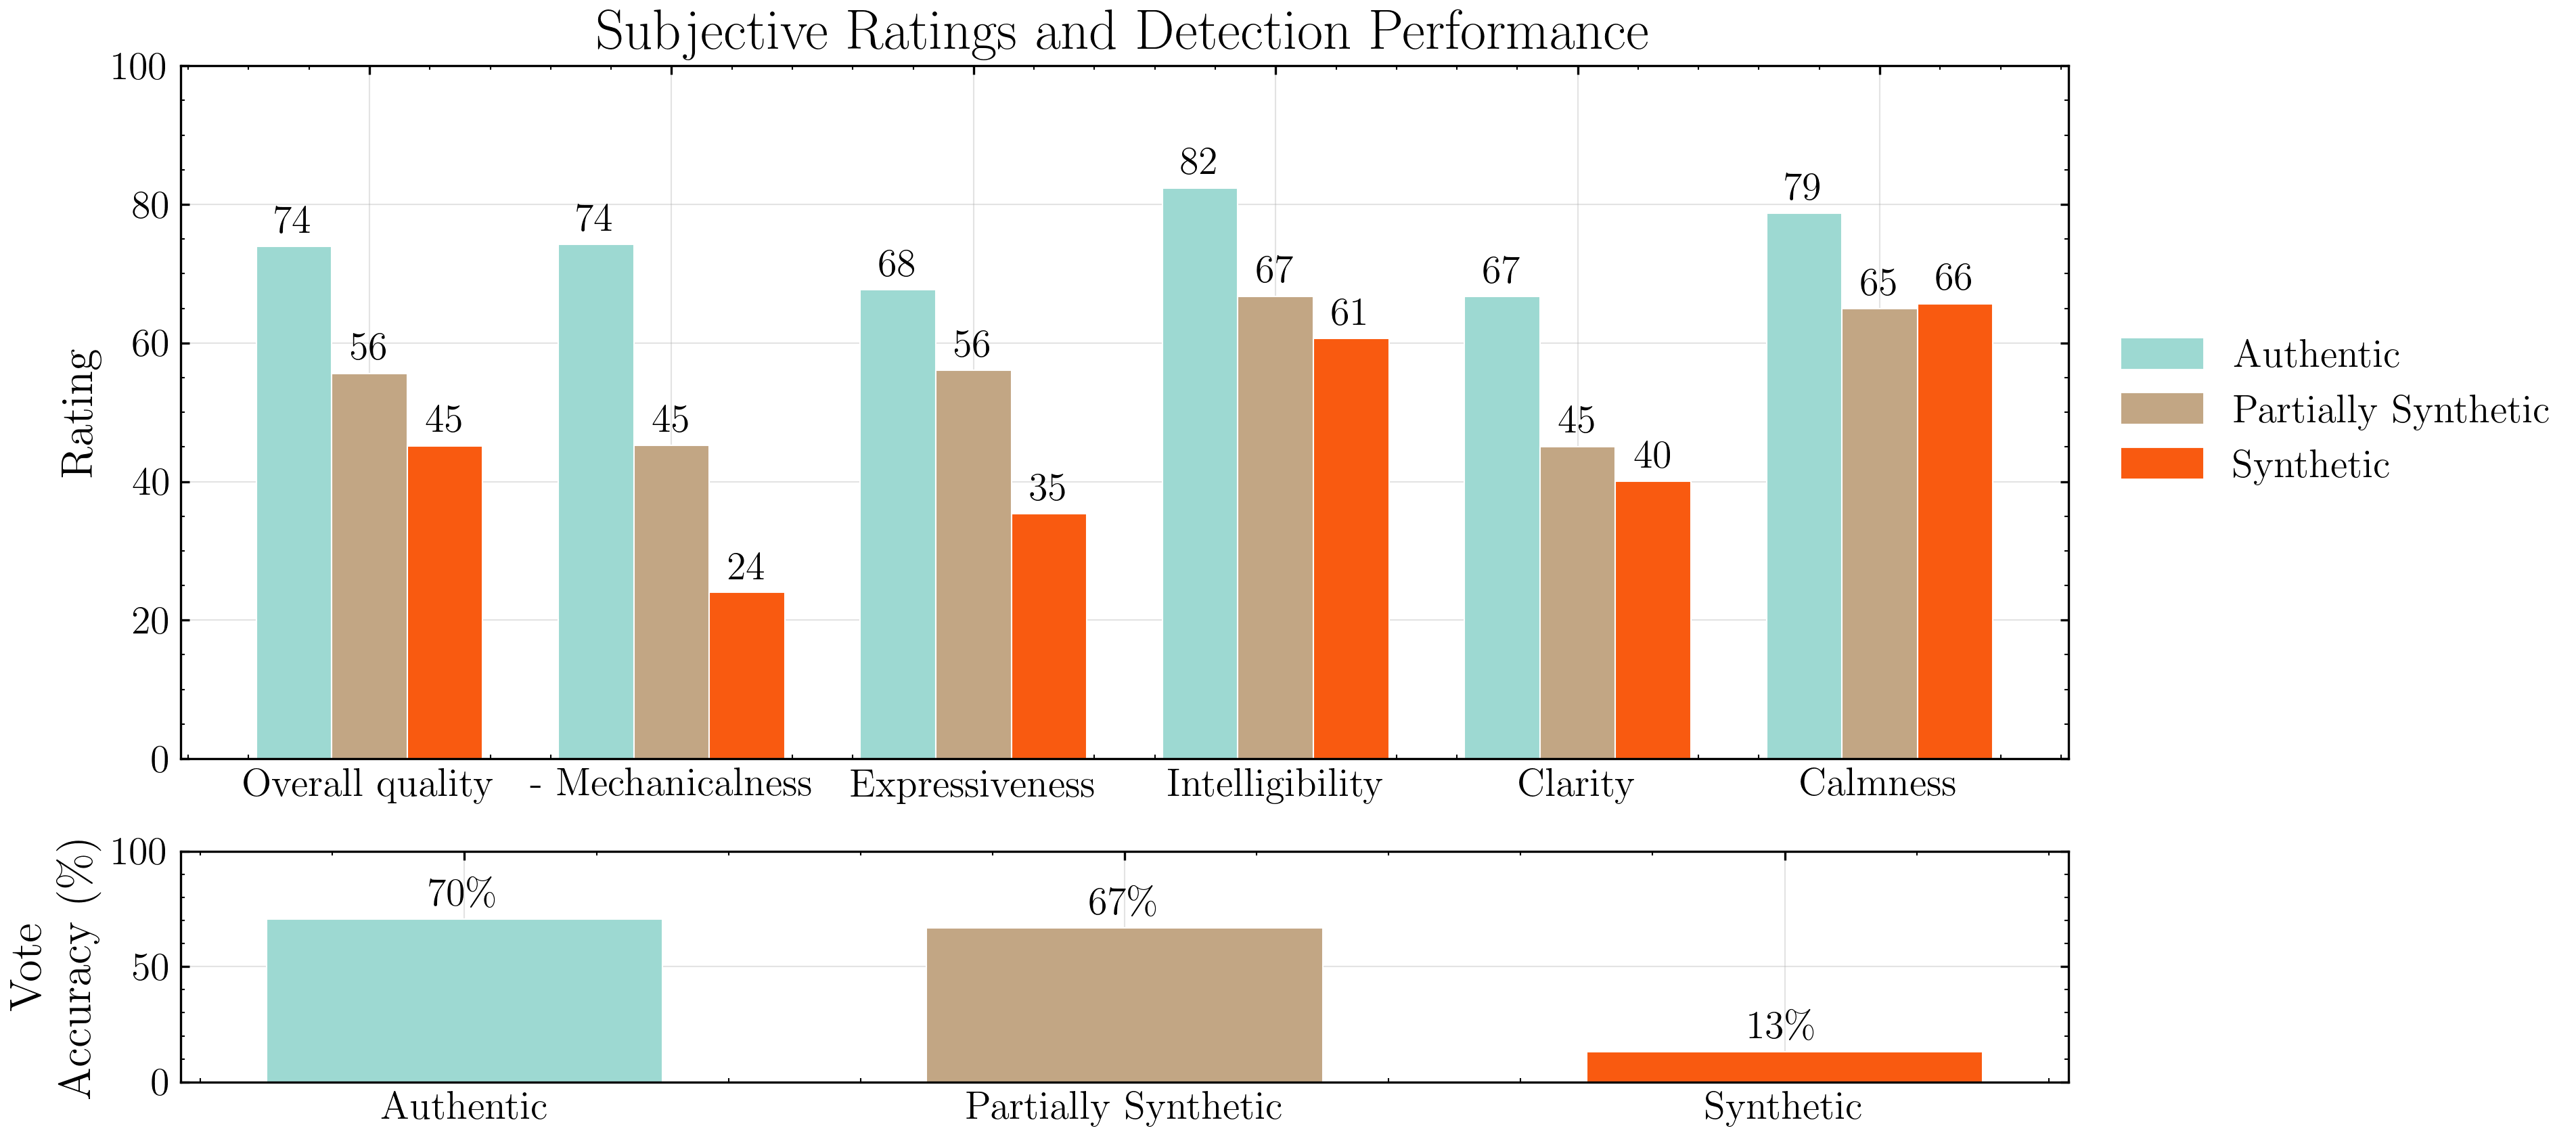

In [74]:
fig, (axT, axB) = plt.subplots(2, 1, figsize=(12, 6.5),
                gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.2})

by_type.T.plot.bar(ax=axT, color=[COLORS[t] for t in UTYPE_ORDER],
                   edgecolor='white', lw=0.5, width=0.75, legend=False)
for c in axT.containers:
    axT.bar_label(c, fmt='%.0f', padding=2)
axT.set_ylabel('Rating')
axT.set_ylim(0, 100)
axT.set_xticklabels(order, rotation=0)
axT.set_xlabel('')
axT.set_title('Subjective Ratings and Detection Performance')
axT.legend([plt.Rectangle((0, 0), 1, 1, color=COLORS[t]) for t in UTYPE_ORDER],
           UTYPE_ORDER, loc='center left', bbox_to_anchor=(1.01, 0.5))

xb = np.arange(len(UTYPE_ORDER))
bars = axB.bar(xb, vote_by_type.values, color=[COLORS[t] for t in UTYPE_ORDER],
               edgecolor='white', lw=0.5, width=0.6)
axB.bar_label(bars, fmt='%.0f\%%', padding=2)
axB.set_xticks(xb)
axB.set_xticklabels(UTYPE_ORDER)
axB.set_ylim(0, 100)
axB.set_ylabel('Vote \nAccuracy (\%)')
plt.show()

# Detection Performance

Participants marked regions they believed synthetic.

- **Window level** (0.2 s): TP/TN/FP/FN against ground-truth segments. User marks are widened by `USER_MARGIN_SEC` before scoring to account fore tool-originated errors. A window counts as synthetic if the *centre* falls inside a ground-truth segment.
- **Clip level**: no marks -> Authentic; coverage ≥ 70% -> Synthetic; anything else -> Partially Synthetic.

#### Windowed accuracy

d' and criterion are pooled per participant from window-level hits and false alarms. Partial clips contribute to both (synthetic windows to hits, their authentic windows to false alarms).


In [11]:
EPS = 1e-4

def compute_sdt(df):
    rows = []
    for pid in df.participant_id.unique():
        p = df[df.participant_id == pid]
        fake = p[p.utterance_type.isin(['Synthetic', 'Partially Synthetic'])]
        real = p[p.utterance_type.isin(['Authentic', 'Partially Synthetic'])]
        TP, FN = fake.TP.sum(), fake.FN.sum()
        FP, TN = real.FP.sum(), real.TN.sum()
        H = TP / (TP + FN) if TP + FN > 0 else np.nan
        FA = FP / (FP + TN) if FP + TN > 0 else np.nan
        if pd.isna(H) or pd.isna(FA):
            continue
        H = float(np.clip(H, EPS, 1 - EPS))
        FA = float(np.clip(FA, EPS, 1 - EPS))
        rows.append({'participant_id': pid, 'experiment': p.experiment.iloc[0],
                     'd_prime': norm.ppf(H) - norm.ppf(FA), 'criterion': -norm.ppf(FA),
                     'H': H, 'FA': FA})
    return pd.DataFrame(rows)

sdt = compute_sdt(df)
print(sdt[['d_prime', 'criterion', 'H', 'FA']].mean().round(3))

d_prime     0.443
criterion   1.465
H           0.254
FA          0.118
dtype: float64


#### Voting Accuracy

For the voting accuracy, we first account for the fact that to obtain a synthetic verdict implied adding markers (aka, an action), while for an authentic verdict the listener does not have to do anything (inaction, less effort). To find real "chance" leveles, we simulate a  version of the experiment 200 times, each time, for each participant, randomly shuffling their votes across their trials. This way, we can ask: if votes were just randomly distributed across clip types, what accuracy would we expect?

In [12]:
rng = np.random.default_rng(0)

def _perm_acc(g):
    return pd.Series(rng.permutation(g.participant_vote.to_numpy()) == g.utterance_type.to_numpy(),
                     index=g.index)

perm = pd.concat([df.groupby('participant_id', group_keys=False).apply(_perm_acc)
                  for _ in range(200)], axis=1)

chance = perm.groupby(df.utterance_type, observed=True).mean().mean(axis=1) * 100
obs = df.groupby('utterance_type', observed=True).vote_correct.mean()
print('df:')
print(pd.DataFrame({'observed %': obs, 'permuted chance %': chance}).round(1), '\n')

by_exp = pd.DataFrame({
    'observed %': df.groupby(['experiment', 'utterance_type'], observed=True).vote_correct.mean(),
    'permuted chance %': (perm.groupby([df.experiment, df.utterance_type], observed=True)
                          .mean().mean(axis=1) * 100)})
print(by_exp.round(1), '\n')

print(sdt.groupby('experiment')[['d_prime', 'criterion', 'H', 'FA']].mean().round(2))
for m in ['d_prime', 'criterion']:
    u = mannwhitneyu(*[g[m].values for _, g in sdt.groupby('experiment')])
    print(f'{m:10s} online vs in-person: U={u.statistic:.0f} p={u.pvalue:.3f}')

df:
                     observed %  permuted chance %
utterance_type                                    
Authentic                70.400             36.700
Partially Synthetic      66.700             55.100
Synthetic                13.100              7.900 

                                       observed %  permuted chance %
experiment        utterance_type                                    
Exp 1 (online)    Authentic                69.800             37.600
                  Partially Synthetic      67.400             58.200
                  Synthetic                 1.700              4.100
Exp 2 (in-person) Authentic                72.000             34.600
                  Partially Synthetic      65.000             48.000
                  Synthetic                40.000             16.900 

                   d_prime  criterion     H    FA
experiment                                       
Exp 1 (online)       0.420      1.640 0.190 0.070
Exp 2 (in-person)    0.490      1.0

In [13]:
MEASURES = {'Vote acc. (%)': 'vote_correct',
            'Marking acc. (%)': 'accuracy',
            'Quality score': 'quality_score'}

def summarize(df, label):
    pmean = (df.groupby(['participant_id', 'utterance_type'], observed=True)[list(MEASURES.values())]
               .mean().reset_index())
    g = pmean.groupby('utterance_type', observed=True)
    out = {}
    for name, col in MEASURES.items():
        m, sd = g[col].mean().reindex(UTYPE_ORDER), g[col].std().reindex(UTYPE_ORDER)
        out[(label, name)] = [f'{mi:.1f} ± {si:.1f}' for mi, si in zip(m, sd)]
    out[(label, 'n ppl')] = g.size().reindex(UTYPE_ORDER).values
    return pd.DataFrame(out, index=UTYPE_ORDER)

exp1 = summarize(df[df.experiment == 'Exp 1 (online)'], 'Exp 1 (online)')
exp2 = summarize(df[df.experiment == 'Exp 2 (in-person)'], 'Exp 2 (in-person)')
both = summarize(df, 'df')

results = pd.concat([exp1, exp2, both], axis=1)
results.columns = pd.MultiIndex.from_tuples(results.columns)
results.index.name = 'Utterance type'
results

Exp 1 (online)                                       \
                     Vote acc. (%) Marking acc. (%) Quality score n ppl   
Utterance type                                                            
Authentic              69.8 ± 28.9        1.0 ± 0.1   74.9 ± 10.2    47   
Partially Synthetic    67.4 ± 18.4        0.6 ± 0.1   57.0 ± 11.2    47   
Synthetic                1.7 ± 5.6        0.1 ± 0.1   46.0 ± 13.1    47   

                    Exp 2 (in-person)                                       \
                        Vote acc. (%) Marking acc. (%) Quality score n ppl   
Utterance type                                                               
Authentic                 72.0 ± 26.3        0.9 ± 0.2   71.8 ± 10.9    20   
Partially Synthetic       65.0 ± 24.6        0.6 ± 0.1   52.4 ± 10.3    20   
Synthetic                 40.0 ± 33.1        0.5 ± 0.3   43.1 ± 10.3    20   

                               df                                       
                    Vote acc. (%) Marking acc. (%) Quality score n ppl  
Utterance type                                                          
Authentic             70.4 ± 27.9        1.0 ± 0.1   74.0 ± 10.4    67  
Partially Synthetic   66.7 ± 20.3        0.6 ± 0.1   55.6 ± 11.1    67  
Synthetic             13.1 ± 25.5        0.2 ± 0.3   45.2 ± 12.3    67

# Hypotheses

**H_A: Overt Detection.** Listeners can discriminate synthetic from authentic speech above chance, as measured by non-zero sensitivity (d′ > 0) at the window level and vote accuracy exceeding the permutation null for each utterance type.

**H_B:Perceptual Calibration.** Listeners' subjective quality ratings track the degree of synthesis, discriminating between the 3 utterance types presented across the composite score and each individual dimension.

#### H_A - Detection

In [14]:
rng = np.random.default_rng(42)
N_PERM = 2000

def perm_vote_acc(df, n_perm=N_PERM):
    """Permute utterance_type within participant, return per-type mean accuracy."""
    results = {ut: [] for ut in UTYPE_ORDER}
    for _ in range(n_perm):
        shuf = (df.groupby('participant_id', group_keys=False)
                  .apply(lambda g: g.assign(
                      utterance_type=rng.permutation(g.utterance_type.to_numpy()))))
        for ut in UTYPE_ORDER:
            sub = shuf[shuf.utterance_type == ut]
            results[ut].append((sub.participant_vote == sub.utterance_type).mean())
    return {ut: np.array(v) for ut, v in results.items()}

null_dist = perm_vote_acc(df)

obs_acc = {ut: (df[df.utterance_type == ut]
                .apply(lambda r: r.participant_vote == r.utterance_type, axis=1)
                .mean())
           for ut in UTYPE_ORDER}

print("H_A: Detection - vote accuracy vs within-participant permutation null\n")
rows = []
for ut in UTYPE_ORDER:
    obs_v = obs_acc[ut]
    null_v = null_dist[ut]
    p_right = (null_v >= obs_v).mean()
    rows.append({'type': ut,
                 'observed_%': obs_v * 100,
                 'null_mean_%': null_v.mean() * 100,
                 'null_sd_%': null_v.std() * 100,
                 'p_right': p_right})

det_df = pd.DataFrame(rows)
det_df['p_fdr'] = multipletests(det_df.p_right, method='fdr_bh')[1]
print(det_df.round(3).to_string(index=False))

print(f"\nd' one-sample Wilcoxon vs 0 (H: d'>0):")
w_dp = wilcoxon(sdt['d_prime'], alternative='greater')
print(f"  mean d'={sdt.d_prime.mean():.3f}  W={w_dp.statistic:.0f}  p={w_dp.pvalue:.4f}")

H_A: Detection - vote accuracy vs within-participant permutation null

               type  observed_%  null_mean_%  null_sd_%  p_right  p_fdr
          Authentic      70.448       36.879      2.068    0.000  0.000
Partially Synthetic      66.716       55.186      1.244    0.000  0.000
          Synthetic      13.134        7.978      1.234    0.000  0.000

d' one-sample Wilcoxon vs 0 (H: d'>0):
  mean d'=0.443  W=1766  p=0.0000


In [15]:
print("SDT summary\n")
sdt_stats = sdt[['d_prime', 'criterion', 'H', 'FA']].agg(['mean', 'sem', 'median'])
print(sdt_stats.round(3))

print("\nPer experiment:")
print(sdt.groupby('experiment')[['d_prime', 'criterion']].agg(['mean', 'sem']).round(3))

# One-sample tests: is criterion != 0?
w_crit = wilcoxon(sdt['criterion'], alternative='two-sided')
print(f"\nCriterion Wilcoxon vs 0: W={w_crit.statistic:.0f}  p={w_crit.pvalue:.4f}")
print(f"Criterion mean={sdt.criterion.mean():.3f}")

SDT summary

        d_prime  criterion     H    FA
mean      0.443      1.465 0.254 0.118
sem       0.077      0.094 0.025 0.014
median    0.519      1.523 0.256 0.064

Per experiment:
                  d_prime       criterion      
                     mean   sem      mean   sem
experiment                                     
Exp 1 (online)      0.423 0.102     1.637 0.080
Exp 2 (in-person)   0.488 0.097     1.061 0.232

Criterion Wilcoxon vs 0: W=1  p=0.0000
Criterion mean=1.465


#### verifying if the 70% threshold for a synthetic marker has any influence

In [ ]:
thresholds = [50, 60, 70, 80, 90]
rows = []
for thr in thresholds:
    tmp = df.copy()
    tmp['participant_vote'] = tmp.apply(
        lambda r: vote(r.marker_count, r.coverage_pct, thr=thr), axis=1
    )
    tmp['vote_correct'] = (tmp['participant_vote'] == tmp['utterance_type']).astype(float) * 100
    for ut in UTYPE_ORDER:
        acc = tmp[tmp.utterance_type == ut]['vote_correct'].mean()
        rows.append({'threshold': thr, 'utterance_type': ut, 'vote_acc': acc})

thr_df = pd.DataFrame(rows).pivot(index='threshold', columns='utterance_type', values='vote_acc')
print(thr_df.round(1).to_string())

utterance_type  Authentic  Partially Synthetic  Synthetic
threshold                                                
50                 70.400               63.000     14.600
60                 70.400               65.200     14.000
70                 70.400               66.700     13.100
80                 70.400               67.200     12.200
90                 70.400               71.200     11.900


#### H_B Perceptual separation
Ordinal logistic (cumulative link) regression on the composite quality score, # binned into 5 ordered levels matching the original −2..+2 Likert scale.

In [87]:
# Utterance type as numeric: increasing value = more authentic
utype_numeric = {'Authentic': 2, 'Partially Synthetic': 1, 'Synthetic': 0}
df['utype_numeric'] = df['utterance_type'].map(utype_numeric)

# Five dimensions on their raw -2:2 integer scale.
dims = {
    '(-) Mechanical': 'rating_mechanicalness_rev',
    'Expressive':     'rating_expressiveness',
    'Intelligible':   'rating_intelligibility',
    'Clear':          'rating_clarity',
    'Calm':           'rating_calmness',
}

rows = []
for label, col in dims.items():
    sub = df[['utype_numeric', col]].dropna()
    y = pd.Categorical(sub[col].astype(int),
                       categories=[-2, -1, 0, 1, 2], ordered=True).codes
    res = OrderedModel(y, sub[['utype_numeric']], distr='logit').fit(
        method='bfgs', disp=False
    )
    coef, se = res.params['utype_numeric'], res.bse['utype_numeric']
    rows.append({
        'Dimension': label,
        'OR':    np.exp(coef),
        'CI_lo': np.exp(coef - 1.96 * se),
        'CI_hi': np.exp(coef + 1.96 * se),
        'z':     res.tvalues['utype_numeric'],
        'p':     res.pvalues['utype_numeric'],
    })

dim_ordinal = pd.DataFrame(rows)
dim_ordinal['p_fdr'] = multipletests(dim_ordinal['p'], method='fdr_bh')[1]
dim_ordinal['sig'] = dim_ordinal['p_fdr'].map(
    lambda p: '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else 'ns'
)

print("Cumulative logit per dimension: OR per step increase in authenticity\n")
for _, r in dim_ordinal.iterrows():
    print(f"  {r['Dimension']:18s}  OR={r['OR']:.2f} [{r['CI_lo']:.2f}, {r['CI_hi']:.2f}]"
          f"  z={r['z']:+.2f}  p_fdr={r['p_fdr']:.3e}  {r['sig']}")

Cumulative logit per dimension: OR per step increase in authenticity

  (-) Mechanical      OR=4.54 [3.88, 5.31]  z=+18.81  p_fdr=3.420e-78  ***
  Expressive          OR=2.95 [2.53, 3.43]  z=+13.98  p_fdr=5.004e-44  ***
  Intelligible        OR=2.12 [1.84, 2.46]  z=+10.13  p_fdr=5.305e-24  ***
  Clear               OR=2.11 [1.83, 2.43]  z=+10.33  p_fdr=8.921e-25  ***
  Calm                OR=1.71 [1.48, 1.98]  z=+7.15  p_fdr=8.664e-13  ***


#### Probing inter and between rater reliability

In [79]:
def cronbach_alpha(data):
    """Internal consistency of k items across n observations (trial-level)."""
    k = data.shape[1]
    return (k / (k - 1)) * (1 - data.var(axis=0, ddof=1).sum() / data.sum(axis=1).var(ddof=1))

def icc_two_way_absolute(data):
    """
    ICC(2,1): two-way random effects, absolute agreement, single rater.
    Treats rows as targets (utterances) and columns as raters (participants).
    Returns: icc, 95% CI lower, 95% CI upper.
    """
    n, k = data.shape
    grand_mean = data.mean().mean()

    # Sum of squares
    ss_rows = k * ((data.mean(axis=1) - grand_mean) ** 2).sum()
    ss_cols = n * ((data.mean(axis=0) - grand_mean) ** 2).sum()
    ss_tot  = ((data - grand_mean) ** 2).values.sum()
    ss_err  = ss_tot - ss_rows - ss_cols

    # Mean squares
    ms_rows = ss_rows / (n - 1)
    ms_cols = ss_cols / (k - 1)
    ms_err  = ss_err / ((n - 1) * (k - 1))

    icc = (ms_rows - ms_err) / (ms_rows + (k - 1) * ms_err + k * (ms_cols - ms_err) / n)

    # 95% CI via F-distribution
    f_l = (ms_rows / ms_err) / f_dist.ppf(0.975, n - 1, (n - 1) * (k - 1))
    f_u = (ms_rows / ms_err) * f_dist.ppf(0.975, (n - 1) * (k - 1), n - 1)
    ci_lo = (f_l - 1) / (f_l + k - 1)
    ci_hi = (f_u - 1) / (f_u + k - 1)

    return icc, ci_lo, ci_hi

In [80]:
raw_dims = ['rating_mechanicalness_rev', 'rating_expressiveness',
            'rating_intelligibility', 'rating_clarity', 'rating_calmness']
labels   = ['(-) Mechanical', 'Expressive', 'Intelligible', 'Clear', 'Calm']

# 1. Scale internal consistency at trial level (not participant means)
trial_dims = df[raw_dims].dropna()
alpha_trial = cronbach_alpha(trial_dims)
print(f"Scale internal consistency (trial level, N={len(trial_dims)} trials)")
print(f"  Cronbach's alpha = {alpha_trial:.3f}\n")

Scale internal consistency (trial level, N=1340 trials)
  Cronbach's alpha = 0.791



In [85]:
# 2. Within-rater consistency: alpha per participant across their 20 trials
per_participant_alpha = (
    df.groupby('participant_id')[raw_dims]
      .apply(lambda g: cronbach_alpha(g.dropna()) if len(g.dropna()) > 1 else np.nan)
)
print(f"Within-rater consistency")
print(f"  Mean alpha = {per_participant_alpha.mean():.3f}  "
      f"SD = {per_participant_alpha.std():.3f}  "
      f"range [{per_participant_alpha.min():.3f}, {per_participant_alpha.max():.3f}]")

Within-rater consistency
  Mean alpha = 0.723  SD = 0.184  range [-0.016, 0.981]


In [83]:
# 3. Between-rater agreement on utterances
df['utterance_key'] = df['utterance_filename'].map(
    lambda p: norm_key(os.path.basename(p))
)
utterance_ratings = df.pivot_table(
    index='utterance_key', columns='participant_id',
    values='quality_score', aggfunc='mean'
)
icc, ci_lo, ci_hi = icc_two_way_absolute(utterance_ratings)
print(f"Between-rater agreement on utterances, ICC(2,1) on quality_score")
print(f"  ICC = {icc:.3f}  95% CI [{ci_lo:.3f}, {ci_hi:.3f}]")
print(f"  N utterances = {utterance_ratings.shape[0]}, "
      f"N raters = {utterance_ratings.shape[1]}")

Between-rater agreement on utterances, ICC(2,1) on quality_score
  ICC = 0.425  95% CI [0.358, 0.679]
  N utterances = 20, N raters = 67


In [84]:
# 4. Spearman correlations between dimensions at trial level
corr_mat = trial_dims.corr(method='spearman')
corr_mat.index = labels
corr_mat.columns = labels
print("Spearman correlations between dimensions (trial level)")
print(corr_mat.round(2))

print("\nEach dimension vs composite quality score (trial level)")
for raw, lab in zip(raw_dims, labels):
    r, p = spearmanr(df[raw].dropna(), df.loc[df[raw].notna(), 'quality_score'])
    print(f"  {lab:18s}  rho={r:+.3f}  p={p:.4f}")

Spearman correlations between dimensions (trial level)
                (-) Mechanical  Expressive  Intelligible  Clear  Calm
(-) Mechanical           1.000       0.560         0.470  0.470 0.360
Expressive               0.560       1.000         0.380  0.340 0.260
Intelligible             0.470       0.380         1.000  0.550 0.570
Clear                    0.470       0.340         0.550  1.000 0.460
Calm                     0.360       0.260         0.570  0.460 1.000

Each dimension vs composite quality score (trial level)
  (-) Mechanical      rho=+0.801  p=0.0000
  Expressive          rho=+0.684  p=0.0000
  Intelligible        rho=+0.759  p=0.0000
  Clear               rho=+0.769  p=0.0000
  Calm                rho=+0.645  p=0.0000


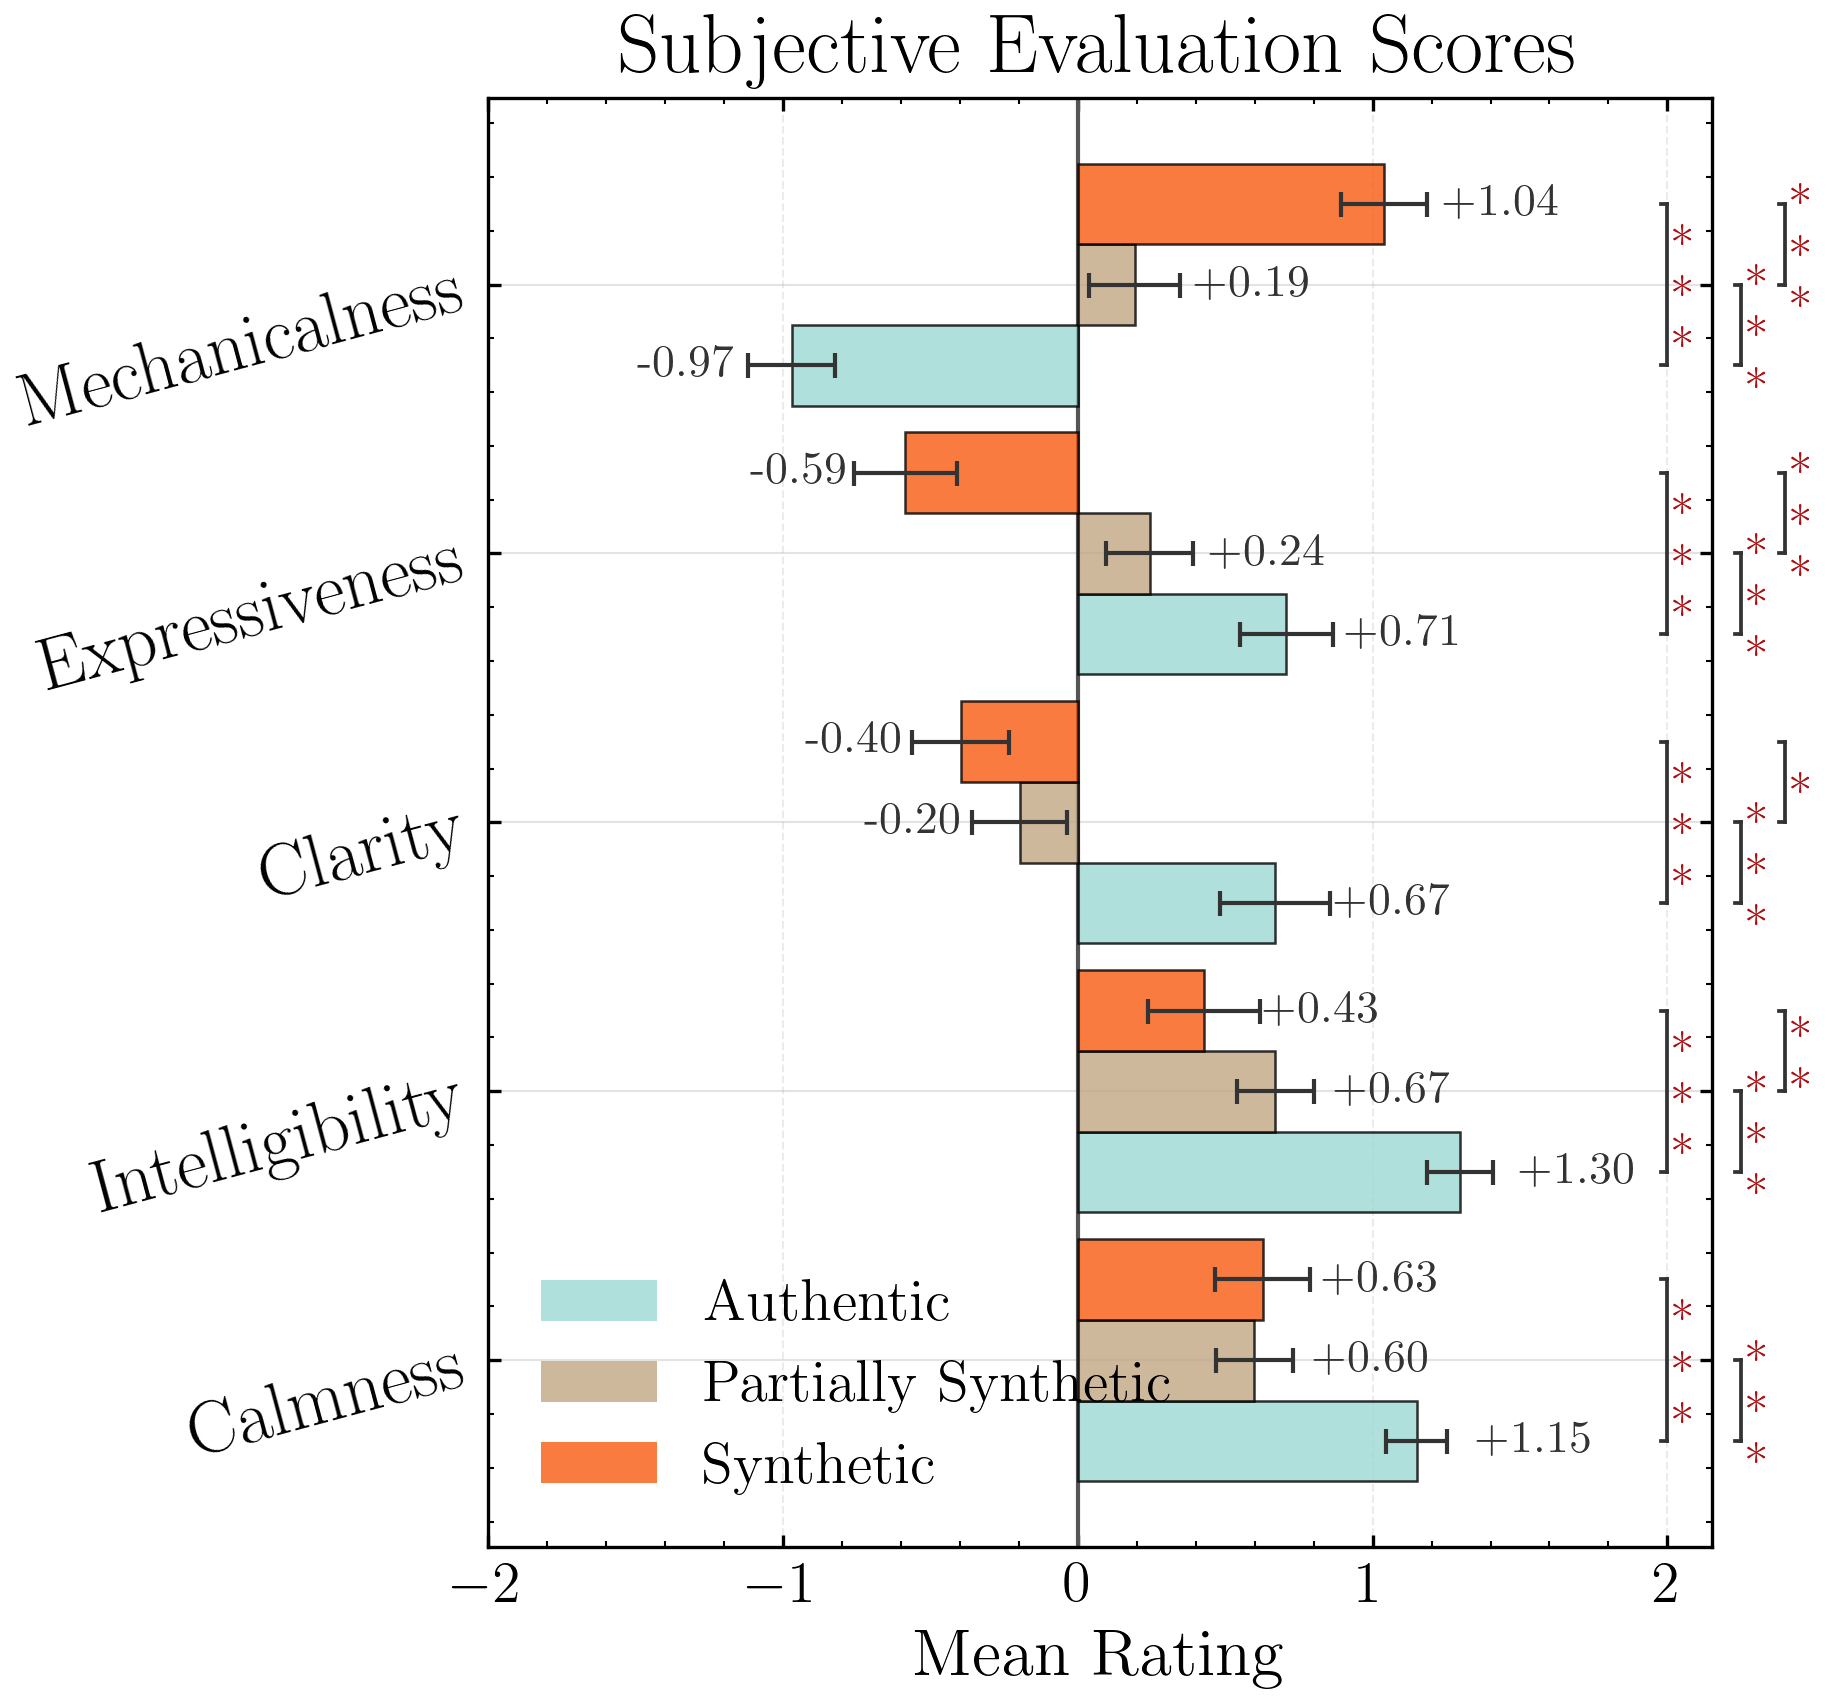

In [18]:
all_dims = ['rating_calmness', 'rating_intelligibility', 'rating_clarity', 'rating_expressiveness', 'rating_mechanicalness']
pm_all = (df.groupby(['participant_id', 'utterance_type'], observed=True)[all_dims].mean().reset_index())
PAIRS = list(combinations(range(3), 2))

fig, ax = plt.subplots(figsize=(8, 6))
bar_h = 0.3
y = np.arange(len(all_dims))
offsets = (np.arange(3) - 1) * bar_h

for j, col in enumerate(all_dims):
    data = [pm_all.loc[pm_all.utterance_type == ut, col].dropna().values for ut in UTYPE_ORDER]
    means = np.array([np.mean(d) for d in data])
    cis = []
    for d in data:
        if len(d) > 1:
            se = np.std(d, ddof=1) / np.sqrt(len(d))
            ci = 1.96 * se
        else:
            ci = np.nan
        cis.append(ci)

    for i, (ut, mean, ci) in enumerate(zip(UTYPE_ORDER, means, cis)):
        yy = y[j] + offsets[i]
        ax.barh(yy, mean, height=bar_h, color=COLORS[ut], alpha=0.8, edgecolor='black', linewidth=0.6, xerr=ci, error_kw=dict(ecolor='#333333', elinewidth=1, capsize=3, capthick=1), zorder=2)
        xpos = mean + 0.2 if mean >= 0 else mean - 0.2
        ha = 'left' if mean >= 0 else 'right'
        ax.text(xpos, yy, f'{mean:+.2f}', ha=ha, va='center', fontsize=11, color='#333333', zorder=4)

    pv = [wilcoxon(data[a], data[b]).pvalue for a, b in PAIRS]
    adj = multipletests(pv, method='holm')[1]

    x_positions = {1: 2, 0: 2.25, 2: 2.4}
    for idx in [1, 0, 2]:
        a, b = PAIRS[idx]
        p_ = adj[idx]
        txt = '*\n*\n*' if p_ < .001 else '*\n*' if p_ < .01 else '*' if p_ < .05 else 'ns'
        if txt != 'ns' or idx == 1:
            ya = y[j] + offsets[a]
            yb = y[j] + offsets[b]
            x = x_positions[idx]
            tick = 0.02
            ax.plot([x, x], [ya, yb], lw=0.9, color='#333333', clip_on=False)
            ax.plot([x - tick, x], [ya, ya], lw=0.9, color='#333333', clip_on=False)
            ax.plot([x - tick, x], [yb, yb], lw=0.9, color='#333333', clip_on=False)
            ax.text(x + 0.02, (ya + yb) / 2, txt, ha='left', va='center', fontsize=12, color='#AB1013', clip_on=False)

ax.axvline(0, color='#555555', lw=1, ls='-', zorder=1)
ax.set_yticks(y)
ax.set_yticklabels([col.replace('rating_', '').replace('_', ' ').title() for col in all_dims], rotation=15, fontsize= 18)
ax.set_xlim(-2, 2.15)
ax.set_xlabel('Mean Rating')
ax.grid(axis='x', alpha=0.25, ls='--', zorder=0)

plt.title("Subjective Evaluation Scores")
legend_handles = [Patch(facecolor=COLORS[ut], alpha=0.8, label=ut) for ut in UTYPE_ORDER]
ax.legend(handles=legend_handles, loc='lower left', frameon=False)
plt.tight_layout(rect=[0, 0, 0.82, 1])
plt.savefig('ratings_bars_likert.svg', dpi=300, bbox_inches='tight')
plt.show()

### Can you separate with just perceptual evaluations?
We test this by training a gradient-boosted classifier separately on (a) observable detection behaviour and (b) the five subjective rating dimensions. GroupKFold cross-validation ensures test participants were never in training, so the balanced accuracy reflects genuine generalisation. 

In [19]:
clf_df = df.dropna(subset=['utterance_filename']).copy()
feat_sub = clf_df[['rating_expressiveness_pct', 'rating_intelligibility_pct',
                    'rating_clarity_pct', 'rating_calmness_pct',
                    'rating_mechanicalness_rev_pct']].fillna(0)

y      = clf_df['utterance_type'].astype(str).values
groups = clf_df['participant_id'].values
cv     = GroupKFold(n_splits=5)

def cv_fold_scores(X):
    clf = HistGradientBoostingClassifier(random_state=0)
    fold_ba, all_pred = [], np.empty(len(y), dtype=object)
    for train, test in cv.split(X, y, groups):
        clf.fit(X[train], y[train])
        pred = clf.predict(X[test])
        all_pred[test] = pred
        fold_ba.append(balanced_accuracy_score(y[test], pred))
    return np.array(fold_ba), all_pred

scores_sub, pred_sub = cv_fold_scores(feat_sub.values)

print(f"Subjective evaluation: BA={scores_sub.mean()*100:.1f}%  SD={scores_sub.std()*100:.1f}")
print(f"Chance (3-class):      33.3%\n")


Subjective evaluation: BA=50.0%  SD=3.7
Chance (3-class):      33.3%



In [20]:
dims = {
    'mechanicalness': 'rating_mechanicalness_rev_pct',
    'expressiveness': 'rating_expressiveness_pct',
    'intelligibility': 'rating_intelligibility_pct',
    'clarity':        'rating_clarity_pct',
    'calmness':       'rating_calmness_pct',
}

all_dims = list(dims.values())
baseline_ba = scores_sub.mean()

print("Leave-one-out dimension importance")
print(f"  Baseline (all dims): BA={baseline_ba*100:.1f}%\n")

loo_rows = []
for name, col in dims.items():
    remaining = [c for c in all_dims if c != col]
    feat_loo  = clf_df[remaining].fillna(0)
    scores_loo, _ = cv_fold_scores(feat_loo.values)
    drop = (baseline_ba - scores_loo.mean()) * 100
    loo_rows.append({'dimension': name,
                     'BA_without': scores_loo.mean() * 100,
                     'BA_drop':    drop})
    print(f"  without {name:15s}: BA={scores_loo.mean()*100:.1f}%  drop={drop:+.1f}%")

loo_df = pd.DataFrame(loo_rows).sort_values('BA_drop', ascending=False)
print(f"\n  Most important dimension: {loo_df.iloc[0].dimension}  "
      f"(drop={loo_df.iloc[0].BA_drop:+.1f}% when removed)")

Leave-one-out dimension importance
  Baseline (all dims): BA=50.0%

  without mechanicalness : BA=45.7%  drop=+4.3%
  without expressiveness : BA=49.6%  drop=+0.4%
  without intelligibility: BA=51.5%  drop=-1.5%
  without clarity        : BA=50.2%  drop=-0.2%
  without calmness       : BA=52.1%  drop=-2.1%

  Most important dimension: mechanicalness  (drop=+4.3% when removed)


# Trust conditions

In [65]:
def get_trust_category(row):
    """Create a "Combined Trust" score for experiment-level analysis from trust cues presented."""
    inst = str(row['condition_instruction']).lower()
    val = str(row['condition_valence']).lower()
    
    if 'monitor' in inst and 'negative' in val:
        return 'High Suspicion \n(I-/V-)'
    elif 'new_tech' in inst and 'positive' in val:
        return 'High Trust(I+/V+)'
    elif ('monitor' in inst and 'positive' in val) or ('new_tech' in inst and 'negative' in val):
        return 'Mixed'
    else:
        return 'Other'

df['trust_category'] = df.apply(get_trust_category, axis=1)
df_clean = df[df['trust_category'] != 'Other'].copy()

In [98]:
metrics_all = [
    'coverage_pct', 
    'vote_correct',  'n_revisions', 'n_refinements', 'trial_duration_sec',
    'TPR','TNR', 
    'rating_expressiveness_pct', 'rating_mechanicalness_pct', 'rating_clarity_pct',
    'rating_intelligibility_pct', 'rating_calmness_pct', 'rating_confidence_pct', 'quality_score',
     'd_prime', 'criterion'
]

valid_cols = [c for c in metrics_all if c in df_clean.columns]
agg_df = df_clean.groupby(['participant_id', 'trust_category'])[valid_cols].mean().reset_index()
print(f"Group Counts: {agg_df['trust_category'].value_counts().to_dict()}\n")


Group Counts: {'Mixed': 28, 'High Trust(I+/V+)': 27, 'High Suspicion \n(I-/V-)': 12}



In [99]:
results_kw = []

for metric in valid_cols:
    groups_list = []
    group_names = []
    
    for name, group in agg_df.groupby('trust_category'):
        groups_list.append(group[metric].dropna())
        group_names.append(name)
    
    if len(groups_list) > 1 and all(len(g) > 1 for g in groups_list):
        try:
            h_stat, p_val = stats.kruskal(*groups_list)
            
            results_kw.append({
                'Metric': metric,
                'H_Statistic': h_stat,
                'P_Value': p_val,
                'Significant': '*' if p_val < 0.05 else ''
            })
            
            sig_mark = '*' if p_val < 0.05 else ''
            print(f"Metric: {metric:<25} | H={h_stat:.2f}, p={p_val:.4f} {sig_mark}")
        except Exception as e:
            print(f"Metric: {metric} -> Error during test: {e}")
    else:
        print(f"Metric: {metric} -> Insufficient data (need >1 per group).")

sig_count = sum(1 for r in results_kw if r['Significant'])

Metric: coverage_pct              | H=3.74, p=0.1538 
Metric: vote_correct              | H=0.19, p=0.9112 
Metric: n_revisions               | H=2.64, p=0.2673 
Metric: n_refinements             | H=2.62, p=0.2700 
Metric: trial_duration_sec        | H=0.63, p=0.7292 
Metric: TPR                       | H=3.25, p=0.1966 
Metric: TNR                       | H=0.83, p=0.6614 
Metric: rating_expressiveness_pct | H=0.45, p=0.8002 
Metric: rating_mechanicalness_pct | H=0.32, p=0.8508 
Metric: rating_clarity_pct        | H=0.82, p=0.6653 
Metric: rating_intelligibility_pct | H=0.65, p=0.7237 
Metric: rating_calmness_pct       | H=0.08, p=0.9628 
Metric: rating_confidence_pct     | H=3.89, p=0.1429 
Metric: quality_score             | H=0.96, p=0.6182 
Metric: d_prime                   | H=1.59, p=0.4524 
Metric: criterion                 | H=1.24, p=0.5373 


#### Effectf of provenance label being shown

In [108]:
#2. Mann-Whitney U per outcome x utterance type (label vs no label)
print("Mann-Whitney U: label shown vs absent, per utterance type")
print(f"{'Utterance type':<22} {'Outcome':<22} {'Label mean':>11} {'No-label mean':>14} {'U':>8} {'p':>8} {'p_fdr':>8}")

rows = []
for utype in UTYPE_ORDER:
    sub = df[df['utterance_type'] == utype]
    shown  = sub[sub['condition_provenance'] == True]
    absent = sub[sub['condition_provenance'] == False]
    for metric in metrics_all:
        a, b = shown[metric].dropna(), absent[metric].dropna()
        if len(a) > 1 and len(b) > 1:
            u, p = mannwhitneyu(a, b, alternative='two-sided')
            rows.append({'utype': utype, 'outcome': metric,
                         'mean_shown': a.mean(), 'mean_absent': b.mean(),
                         'U': u, 'p': p})

mw_df = pd.DataFrame(rows)
mw_df['p_fdr'] = multipletests(mw_df['p'], method='fdr_bh')[1]
mw_df['sig'] = mw_df['p_fdr'].map(
    lambda p: '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else 'ns'
)

for _, r in mw_df.iterrows():
    print(f"{r['utype']:<22} {r['outcome']:<22} {r['mean_shown']:>11.2f} "
          f"{r['mean_absent']:>14.2f} {r['U']:>8.0f} {r['p']:>8.3f} "
          f"{r['p_fdr']:>8.3f} {r['sig']}")


Mann-Whitney U: label shown vs absent, per utterance type
Utterance type         Outcome                 Label mean  No-label mean        U        p    p_fdr
Authentic              coverage_pct                  4.27           3.11    14404    0.503    0.981 ns
Authentic              vote_correct                 70.41          70.48    14018    0.990    0.990 ns
Authentic              n_revisions                   0.09           0.16    14009    0.960    0.981 ns
Authentic              n_refinements                 1.66           1.86    14500    0.538    0.981 ns
Authentic              trial_duration_sec          107.98         127.82    13263    0.389    0.981 ns
Authentic              TNR                           0.94           0.96    13339    0.285    0.981 ns
Authentic              rating_expressiveness_pct       66.72          68.67    13370    0.403    0.981 ns
Authentic              rating_mechanicalness_pct       24.26          27.26    13361    0.424    0.981 ns
Authentic   

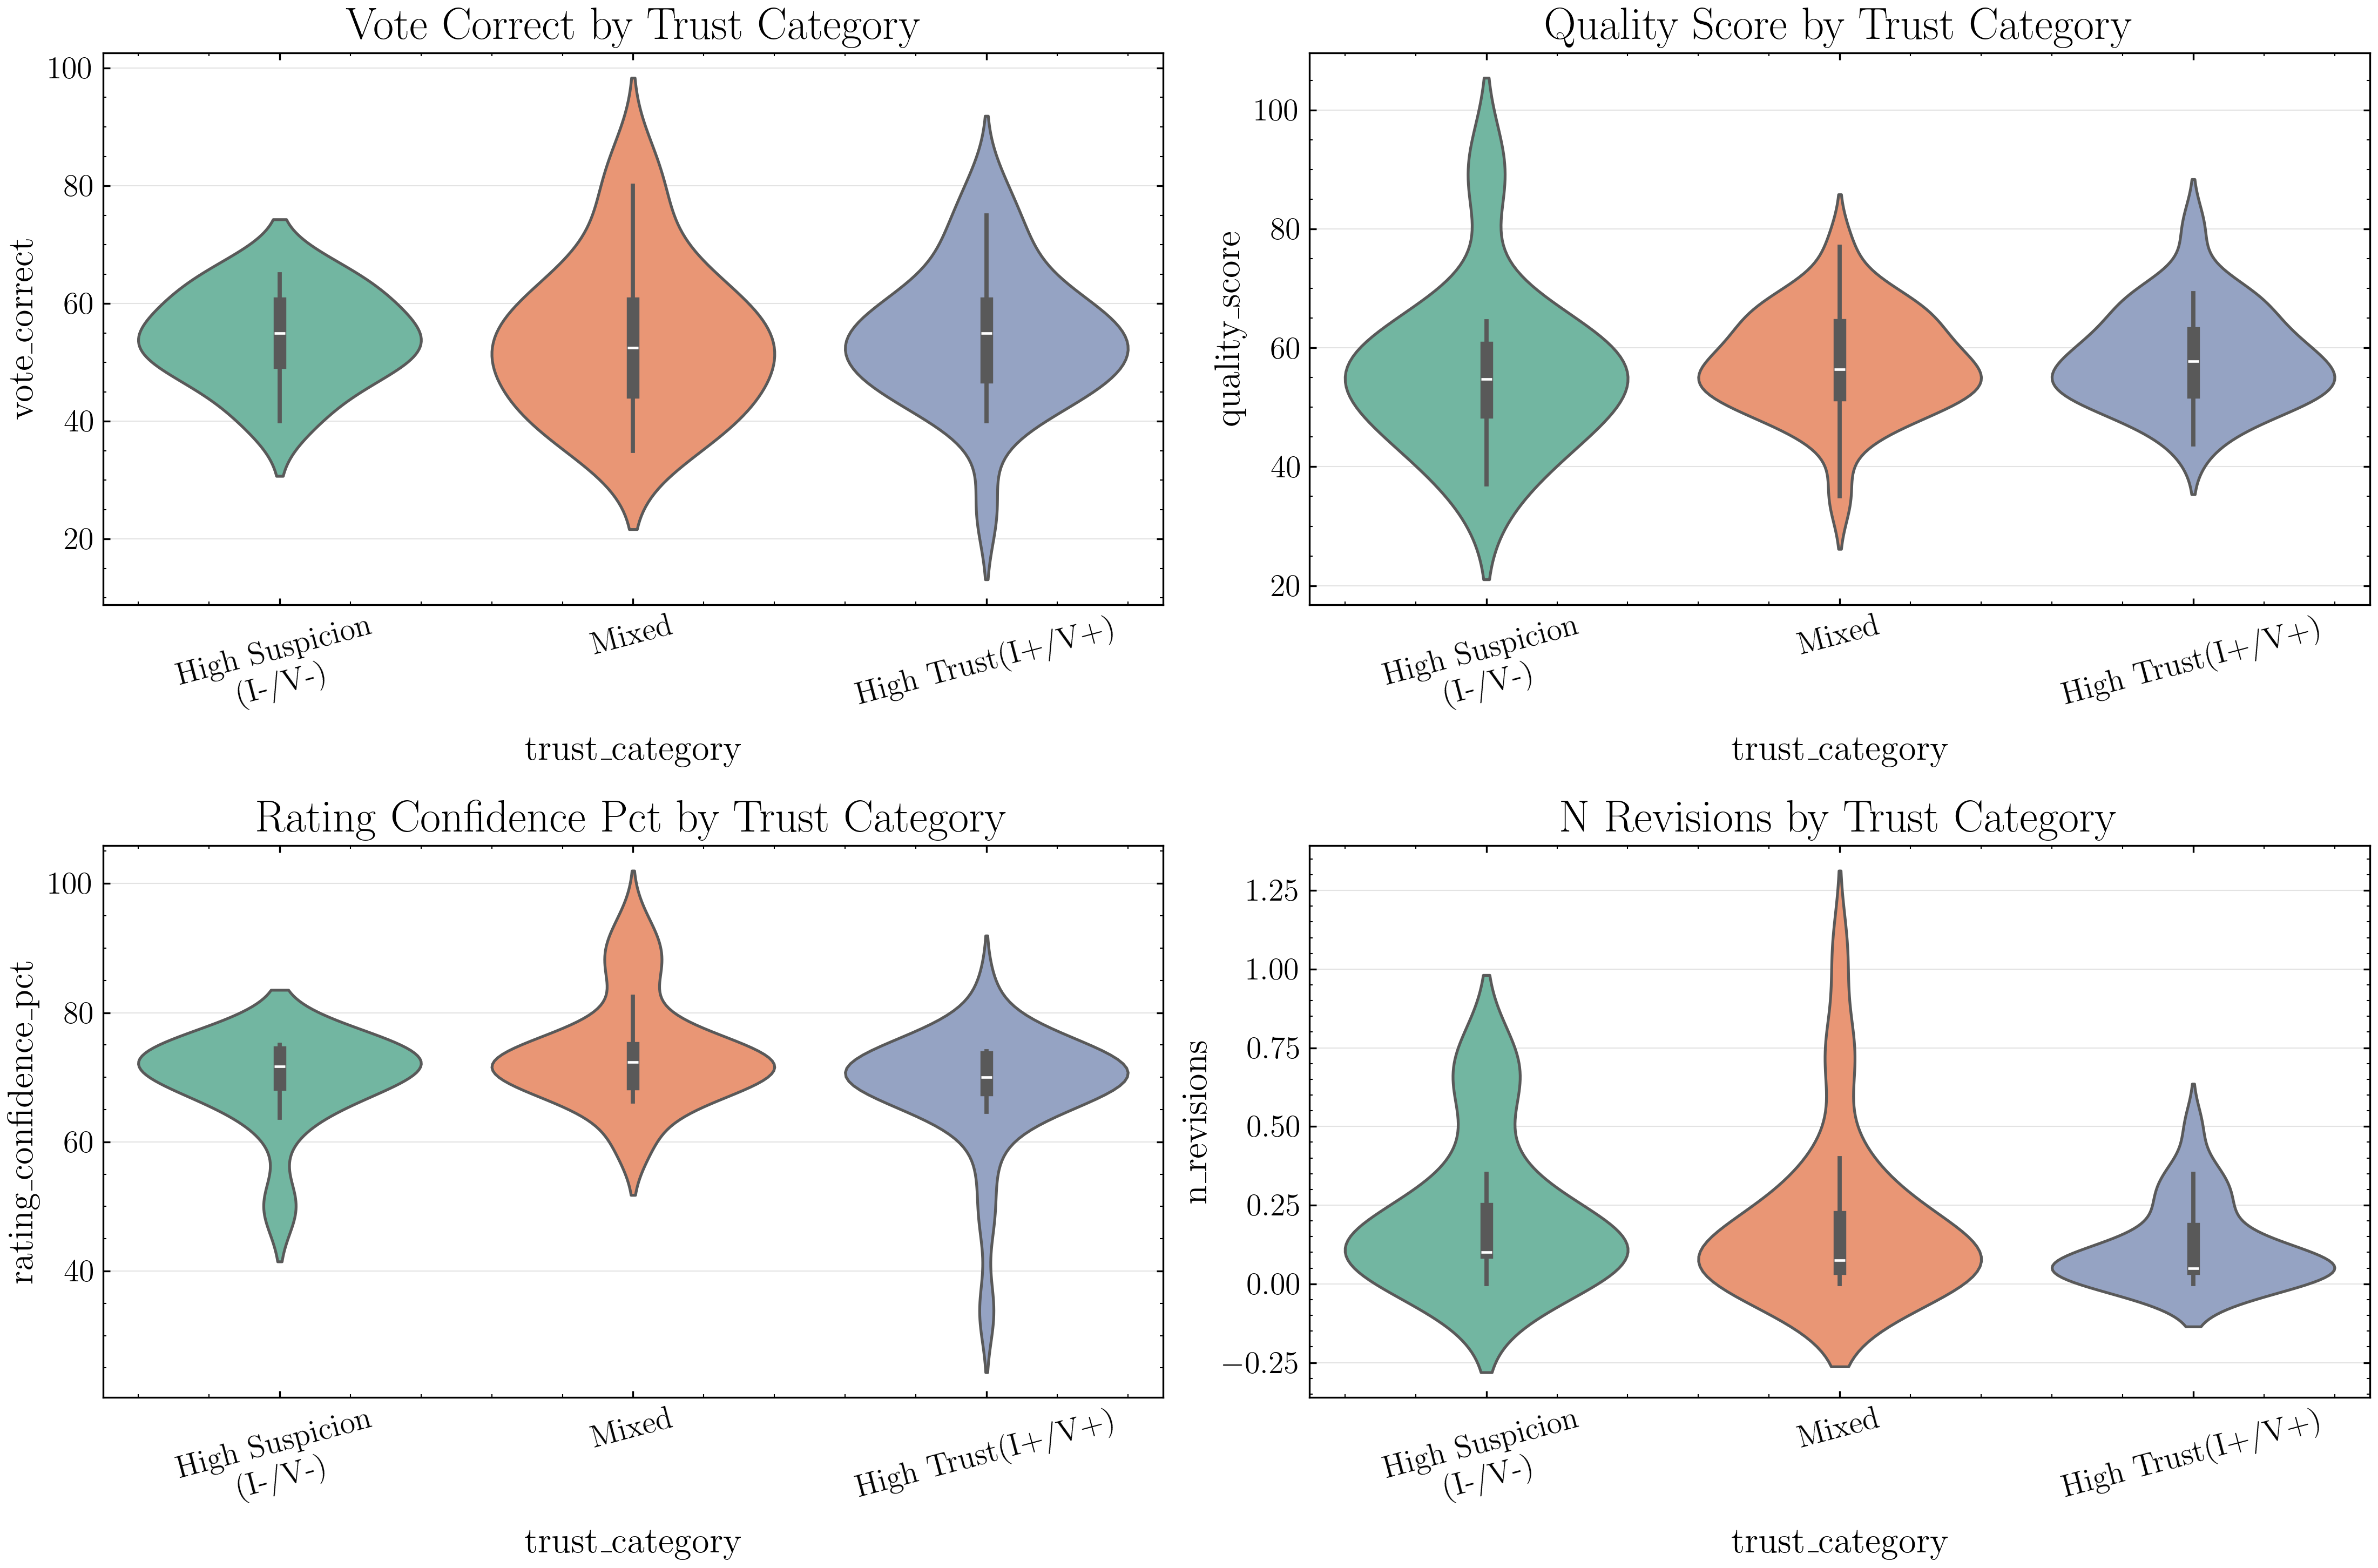

In [72]:
key_metrics = ['vote_correct', 'quality_score', 'rating_confidence_pct', 'n_revisions']
valid_key_metrics = [m for m in key_metrics if m in valid_cols]

if len(valid_key_metrics) > 0:
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    axes = axes.flatten()
    
    order = ['High Suspicion \n(I-/V-)', 'Mixed', 'High Trust(I+/V+)']
    
    for i, metric in enumerate(valid_key_metrics):
        if i < len(axes):
            sns.violinplot(data=agg_df, x='trust_category', y=metric, ax=axes[i], palette='Set2', order=order)
            axes[i].set_title(f'{metric.replace("_", " ").title()} by Trust Category')
            axes[i].tick_params(axis='x', rotation=15)
            
    plt.tight_layout()
    plt.show()